# 03. Бинарная классификация банковских рисков: результаты экспериментов и практическая применимость Deep Learning

**Исследовательская задача:** выявить признаки банковских рисков в русскоязычных новостях (`alert_flag`: 1 — риск, 0 — нет риска) и сравнить классические алгоритмы машинного обучения с дообученной `mDeBERTa-v3-base`.

**Цель сравнения:** выяснить не только, какая модель показывает более высокий F1, но и насколько методы подходят для практического сценария мониторинга: **отправки аналитикам релевантных предупреждений с контролем ложных срабатываний**.

**Экспериментальный протокол:** основная метрика подбора гиперпараметров и порога — **F1 на validation**. Precision и Recall рассматриваются как дополнительные показатели с разной прикладной интерпретацией. При сравнении на test условия фиксируются; **по тестовым метрикам модели не подбираются**.

В работе используются сохранённые результаты **9 запусков mDeBERTa** и классических baseline (TF-IDF + LinearSVC, Logistic Regression). Этот отчёт **не переобучает модели**: он загружает файлы `data/`, независимо пересчитывает Precision, Recall и F1 по матрицам ошибок и строит таблицы, графики и выводы. AP переносится из журналов запусков, поскольку предсказания отдельных примеров есть не для каждой конфигурации.

**Дополнительное исследование:** многоклассовая классификация выполнена по признаку `risk_type_4cls`; результаты приведены в ноутбуках 07 и 11. Исходный датасет и фиксированные разбиения не меняются.

## 1. Загрузка исходных файлов и проверка воспроизводимости

Файлы расположены в каталоге `data/` рядом с ноутбуком. В этой ячейке проверяется их наличие, формат и хеш датасета. Хеш должен совпадать с зафиксированным в `selection.json`: таким образом проверяется, что используются именно те данные, с которыми выполнено обучение нейросети.

In [2]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 55)

DATA_DIR = Path('data')
required = [
    'bank_risk_dataset.csv', 'validation_comparison.csv',
    'seed_stability.csv', 'selection.json', 'baseline_metrics.csv',
    'dl_test_metrics.json',
]
missing = [name for name in required if not (DATA_DIR/name).is_file()]
if missing:
    raise FileNotFoundError(f'Отсутствуют файлы в папке data/: {missing}')

dataset = pd.read_csv(DATA_DIR/'bank_risk_dataset.csv')
experiments = pd.read_csv(DATA_DIR/'validation_comparison.csv')
seeds = pd.read_csv(DATA_DIR/'seed_stability.csv')
baseline = pd.read_csv(DATA_DIR/'baseline_metrics.csv')
with (DATA_DIR/'selection.json').open(encoding='utf-8') as fh:
    selection = json.load(fh)

actual_sha = hashlib.sha256((DATA_DIR/'bank_risk_dataset.csv').read_bytes()).hexdigest()
assert actual_sha == selection['dataset_sha256'], 'Контрольная сумма исходного CSV не совпадает!'
assert dataset['sample_id'].is_unique
assert len(dataset) == 5041 and set(dataset['split']) == {'train','valid','test'}
assert set(experiments['name']) == set(experiments['name'].unique()) and len(experiments) == 9

print('Файлы загружены. Контрольная сумма датасета совпадает.')
print('SHA256:',actual_sha)
print(f'Наблюдений: {len(dataset)}; Deep Learning запусков: {len(experiments)}; seed: {len(seeds)}')

Файлы загружены. Контрольная сумма датасета совпадает.
SHA256: 52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3
Наблюдений: 5041; Deep Learning запусков: 9; seed: 3


## 2. Выборки, дисбаланс и критерии качества

Разбиение `train / valid / test` зафиксировано в исходном датасете. Положительный класс редок, поэтому Accuracy малоинформативна сама по себе.

- **F1 положительного класса** — основной критерий выбора конфигурации на validation; балансирует Precision и Recall.
- **Precision** — доля действительно рисковых новостей среди тех, по которым система выдала предупреждение. Высокая Precision снижает нагрузку от ложных сигналов.
- **Recall** — доля обнаруженных рисковых новостей. Высокая Recall важна, если пропуск банковского риска обходится дорого.

Важный компромисс: уменьшение ложных тревог может сопровождаться ростом числа пропущенных рисков. Поэтому мы **не меняем основную метрику задним числом**, а отдельно оцениваем прикладной профиль ошибок.

,Без риска (0),Есть риск (1),Всего,"Доля риска, %"
split,,,,
train,3359,176,3535,4.98
valid,715,40,755,5.30
test,713,38,751,5.06


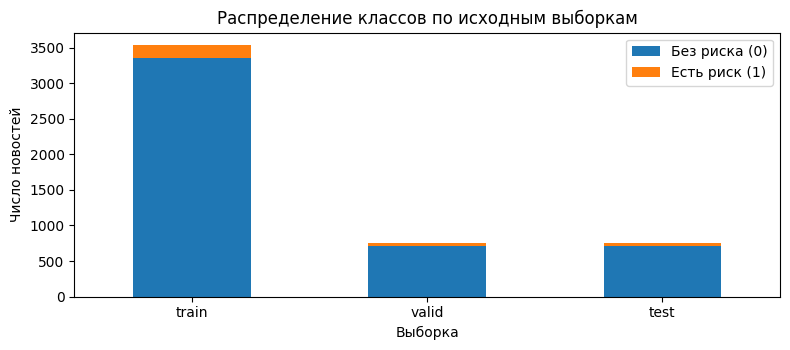

In [3]:
counts = pd.crosstab(dataset['split'],dataset['alert_flag']).reindex(['train','valid','test'])
counts.columns = ['Без риска (0)', 'Есть риск (1)']
counts['Всего'] = counts.sum(axis=1)
counts['Доля риска, %'] = (100 * counts['Есть риск (1)'] / counts['Всего']).round(2)
display(counts)

assert counts.loc['valid','Есть риск (1)'] == 40
assert counts.loc['valid','Без риска (0)'] == 715
assert counts.loc['test','Есть риск (1)'] == 38
assert counts.loc['test','Без риска (0)'] == 713

fig, ax = plt.subplots(figsize=(8, 3.6))
plot_counts = counts[['Без риска (0)','Есть риск (1)']]
plot_counts.plot(kind='bar',stacked=True,ax=ax)
ax.set_title('Распределение классов по исходным выборкам')
ax.set_xlabel('Выборка')
ax.set_ylabel('Число новостей')
ax.tick_params(axis='x',rotation=0)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 3. Формулы метрик и независимый пересчёт

Для бинарной классификации используем элементы матрицы ошибок: **TP** — верно обнаруженные риски, **FP** — ложные тревоги, **FN** — пропущенные риски, **TN** — корректно определённые новости без риска.

\[
Precision = \frac{TP}{TP+FP}, \qquad Recall = \frac{TP}{TP+FN}
\]

\[
F1 = \frac{2\,Precision\cdot Recall}{Precision+Recall}
     = \frac{2TP}{2TP+FP+FN}
\]

Ниже Precision, Recall и F1 пересчитываются **непосредственно из TP, FP, FN**, затем сверяются с результатами обучения. Для AP необходимы оценки риска по каждому наблюдению: в этом ноутбуке она считывается из оригинальных журналов и **не выдаётся за заново рассчитанную метрику**.

In [4]:
def calculate_metrics(rows):
    """Вычислить precision/recall/F1 непосредственно из TP, FP и FN."""
    tp = rows['tp'].astype(float)
    fp = rows['fp'].astype(float)
    fn = rows['fn'].astype(float)
    return pd.DataFrame({
        'precision_calc': (tp/(tp+fp)).fillna(0),
        'recall_calc': (tp/(tp+fn)).fillna(0),
        'f1_calc': (2*tp/(2*tp+fp+fn)).fillna(0),
    },index=rows.index)

for title, frame in [('mDeBERTa',experiments),('Baseline',baseline)]:
    calculated = calculate_metrics(frame)
    for col,calc_col in [('precision','precision_calc'),('recall','recall_calc'),('f1','f1_calc')]:
        assert np.allclose(frame[col].to_numpy(),calculated[calc_col].to_numpy(),atol=1e-10), (title,col)
    print(f'{title}: пересчёт Precision, Recall, F1 совпадает с сохранёнными результатами.')

assert ((experiments['tp']+experiments['fn'])==40).all()
assert ((experiments['tn']+experiments['fp'])==715).all()
assert ((baseline.loc[baseline['split']=='valid','tp'] + baseline.loc[baseline['split']=='valid','fn'])==40).all()

winner_name = selection['selected_run']
assert winner_name in experiments['name'].values
winner = experiments.set_index('name').loc[winner_name]
assert np.isclose(winner['f1'],selection['validation']['f1'])
print(f'Зафиксированный победитель по validation F1: {winner_name} (F1={winner["f1"]:.4f}).')

mDeBERTa: пересчёт Precision, Recall, F1 совпадает с сохранёнными результатами.
Baseline: пересчёт Precision, Recall, F1 совпадает с сохранёнными результатами.
Зафиксированный победитель по validation F1: screen_bank_context (F1=0.7949).


## 4. Сравнение всех конфигураций Deep Learning

Архитектура — `microsoft/mdeberta-v3-base`; в экспериментах сравнивались четыре представления входного текста, функции потерь, learning rate и разные random seed. Все результаты получены на одном неизменённом наборе из **755 validation-примеров**. Основной критерий выбора — **наибольший F1**, при равенстве используется AP.

,Описание,seed,loss_mode,learning_rate,f1,precision,recall,ap,tp,fp,fn
0,Контекст банка,42,standard,0.0,0.7949,0.8158,0.775,0.7466,31,7,9
1,Только текст новости,42,standard,0.0,0.7606,0.8710,0.675,0.8111,27,4,13
2,Контекст + Focal Loss,42,focal,0.0,0.7595,0.7692,0.750,0.8287,30,9,10
3,Банк + текст (пара),42,standard,0.0,0.7500,0.8438,0.675,0.7986,27,5,13
4,Контекст + LR 1e-5,42,standard,0.0,0.7500,0.6875,0.825,0.6822,33,15,7
5,Контекст + seed 2026,2026,standard,0.0,0.7470,0.7209,0.775,0.7506,31,12,9
6,Банк + заголовок + текст,42,standard,0.0,0.7297,0.7941,0.675,0.8333,27,7,13
7,Контекст + Weighted CE,42,weighted,0.0,0.7160,0.7073,0.725,0.7814,29,12,11
8,Контекст + seed 123,123,standard,0.0,0.6977,0.6522,0.750,0.7092,30,16,10


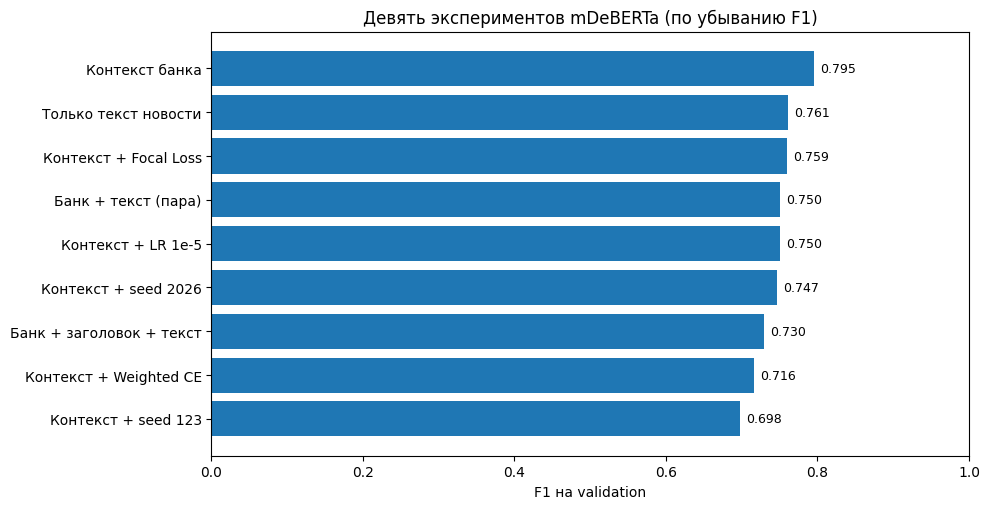

In [5]:
labels = {
    'screen_text':'Только текст новости',
    'screen_bank_pair':'Банк + текст (пара)',
    'screen_bank_title':'Банк + заголовок + текст',
    'screen_bank_context':'Контекст банка',
    'tune_bank_context_weighted':'Контекст + Weighted CE',
    'tune_bank_context_focal':'Контекст + Focal Loss',
    'tune_bank_context_lr1e5':'Контекст + LR 1e-5',
    'repeat_bank_context_standard_123':'Контекст + seed 123',
    'repeat_bank_context_standard_2026':'Контекст + seed 2026',
}
comparison = experiments.sort_values(['f1','ap'],ascending=False).copy()
comparison.insert(1,'Описание',comparison['name'].map(labels).fillna(comparison['name']))
display(comparison[['Описание','seed','loss_mode','learning_rate','f1','precision','recall','ap','tp','fp','fn']].round(4).reset_index(drop=True))

fig,ax=plt.subplots(figsize=(10,5.2))
y = np.arange(len(comparison))
ax.barh(y,comparison['f1'])
ax.set_yticks(y,comparison['Описание'])
ax.invert_yaxis()
ax.set_xlim(0,1)
ax.set_xlabel('F1 на validation')
ax.set_title('Девять экспериментов mDeBERTa (по убыванию F1)')
for k,v in enumerate(comparison['f1']):
    ax.text(v+0.008,k,f'{v:.3f}',va='center',fontsize=9)
plt.tight_layout()
plt.show()

## 5. Анализ гипотез: входные данные, потери, скорость обучения

В этом разделе сравниваем конфигурации **внутри семейства mDeBERTa**. Так мы видим, какие изменения в постановке обучения сработали на validation, не обращаясь к test.

In [6]:
screen = experiments[experiments['name'].str.startswith('screen_')].copy()
tune = experiments[(experiments['mode']=='bank_context') & (experiments['seed']==42)].copy()
print('Представление новости:')
display(screen[['name','f1','precision','recall','ap']].sort_values('f1',ascending=False).round(4))
print('Функции потерь и learning rate (один формат входа и seed 42):')
display(tune[['name','loss_mode','learning_rate','f1','precision','recall','ap']].sort_values('f1',ascending=False).round(4))

base_context = experiments.set_index('name').loc['screen_bank_context']
for name in ['tune_bank_context_weighted','tune_bank_context_focal','tune_bank_context_lr1e5']:
    other=experiments.set_index('name').loc[name]
    print(f'{labels[name]:<28} ΔF1={other["f1"]-base_context["f1"]:+.4f}; ΔAP={other["ap"]-base_context["ap"]:+.4f}')

Представление новости:


,name,f1,precision,recall,ap
0,screen_bank_context,0.7949,0.8158,0.775,0.7466
1,screen_text,0.7606,0.8710,0.675,0.8111
3,screen_bank_pair,0.7500,0.8438,0.675,0.7986
6,screen_bank_title,0.7297,0.7941,0.675,0.8333


Функции потерь и learning rate (один формат входа и seed 42):


,name,loss_mode,learning_rate,f1,precision,recall,ap
0,screen_bank_context,standard,0.0,0.7949,0.8158,0.775,0.7466
2,tune_bank_context_focal,focal,0.0,0.7595,0.7692,0.750,0.8287
4,tune_bank_context_lr1e5,standard,0.0,0.7500,0.6875,0.825,0.6822
7,tune_bank_context_weighted,weighted,0.0,0.7160,0.7073,0.725,0.7814


Контекст + Weighted CE       ΔF1=-0.0788; ΔAP=+0.0348
Контекст + Focal Loss        ΔF1=-0.0354; ΔAP=+0.0820
Контекст + LR 1e-5           ΔF1=-0.0449; ΔAP=-0.0644


## 6. Бинарный baseline и сравнение на validation

В качестве классических моделей применены **TF-IDF + LinearSVC** и **TF-IDF + Logistic Regression**; для контроля показан DummyClassifier. Метрики взяты из сохранённых протоколов, в которых подбор параметров производился по validation F1.

Основной научный результат здесь — преимущество конфигурации mDeBERTa по **валидационному F1**. Но это ещё не означает, что она будет превосходить baseline на независимых данных по всем метрикам: далее проверяется конкретный профиль ошибок на test.

,Модель,f1,precision,recall,ap,tp,fp,fn,tn
0,mDeBERTa (контекст банка),0.7949,0.8158,0.775,0.7466,31,7,9,708
1,LinearSVC,0.7532,0.7838,0.725,0.7561,29,8,11,707
2,LogisticRegression,0.7273,0.7568,0.700,0.7606,28,9,12,706
3,DummyClassifier,0.1006,0.0530,1.000,0.0530,40,715,0,0


Лучший классический baseline на valid: LinearSVC, F1=0.7532
mDeBERTa: F1=0.7949; разница = +0.0416 пункта F1


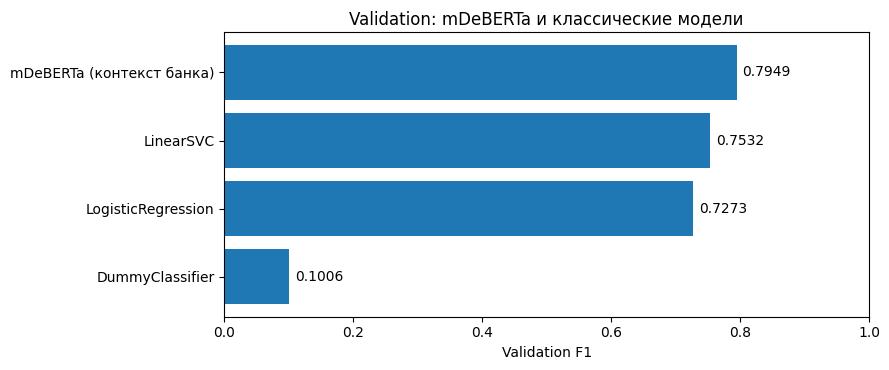

In [7]:
base_valid = baseline[baseline['split']=='valid'].copy()
base_valid['Модель'] = base_valid['model']
dl_valid = pd.DataFrame([{
    'Модель':'mDeBERTa (контекст банка)',
    'f1':float(winner['f1']),
    'precision':float(winner['precision']),
    'recall':float(winner['recall']),
    'ap':float(winner['ap']),
    'tp':int(winner['tp']),'fp':int(winner['fp']),
    'fn':int(winner['fn']),'tn':int(winner['tn']),
}])
valid_ranking = pd.concat([
    base_valid[['Модель','f1','precision','recall','ap','tp','fp','fn','tn']],
    dl_valid
],ignore_index=True).sort_values('f1',ascending=False).reset_index(drop=True)
display(valid_ranking.round(4))

best_classic = base_valid.loc[base_valid['model'].ne('DummyClassifier')].sort_values('f1',ascending=False).iloc[0]
delta = float(winner['f1']-best_classic['f1'])
print(f'Лучший классический baseline на valid: {best_classic["model"]}, F1={best_classic["f1"]:.4f}')
print(f'mDeBERTa: F1={winner["f1"]:.4f}; разница = {delta:+.4f} пункта F1')

fig,ax=plt.subplots(figsize=(9,3.8))
ax.barh(valid_ranking['Модель'],valid_ranking['f1'])
ax.invert_yaxis()
ax.set_xlim(0,1)
ax.set_xlabel('Validation F1')
ax.set_title('Validation: mDeBERTa и классические модели')
for k,v in enumerate(valid_ranking['f1']):
    ax.text(v+0.009,k,f'{v:.4f}',va='center')
plt.tight_layout()
plt.show()

## 7. Как устроены ошибки лучших моделей на validation

Матрица ошибок показывает цену классификационных решений: **FP** — ложные тревоги, **FN** — пропущенные новости о риске. Мы используем ровно те числа, которые были сохранены в экспериментах. Это **не новая инференс-оценка**.

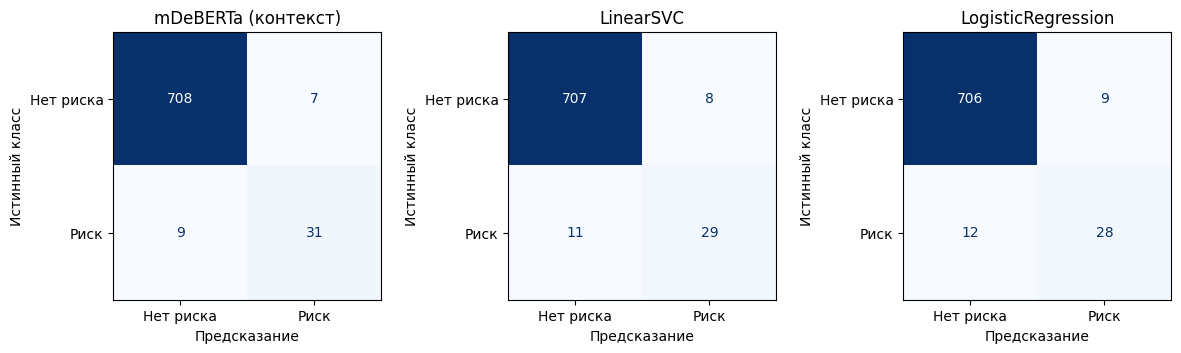

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

example_rows = [
    ('mDeBERTa (контекст)',winner),
    ('LinearSVC',base_valid.set_index('model').loc['LinearSVC']),
    ('LogisticRegression',base_valid.set_index('model').loc['LogisticRegression']),
]
fig,axes = plt.subplots(1,3,figsize=(12,3.6))
for ax,(name,row) in zip(axes,example_rows):
    matrix = np.array([[int(row['tn']),int(row['fp'])],[int(row['fn']),int(row['tp'])]])
    ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=['Нет риска','Риск']).plot(
        ax=ax,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title(name)
    ax.set_xlabel('Предсказание')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

## 8. Проверка устойчивости к random seed

Три запуска одной конфигурации различались только значением `seed`. Это **не три независимые выборки**: все они оценивались на одном validation-наборе. Мы рассчитываем среднее и **выборочное стандартное отклонение** F1, чтобы показать чувствительность обучения к инициализации и перемешиванию примеров. Это не доверительный интервал качества на новых данных.

,seed,f1,ap
0,42,0.7949,0.7466
1,123,0.6977,0.7092
2,2026,0.7470,0.7506


F1: среднее=0.7465, выборочное SD=0.0486, min=0.6977, max=0.7949


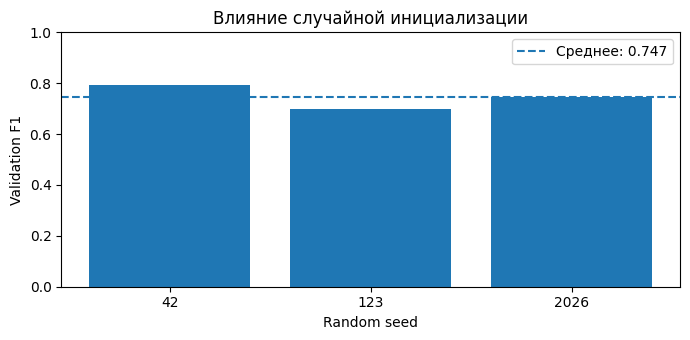

In [9]:
seed_results = seeds.sort_values('seed').copy()
seed_results['seed'] = seed_results['seed'].astype(int)
display(seed_results[['seed','f1','ap']].round(4).reset_index(drop=True))
seed_mean = seed_results['f1'].mean()
seed_sd = seed_results['f1'].std(ddof=1)
print(f'F1: среднее={seed_mean:.4f}, выборочное SD={seed_sd:.4f}, min={seed_results["f1"].min():.4f}, max={seed_results["f1"].max():.4f}')

fig, ax = plt.subplots(figsize=(7,3.5))
ax.bar(seed_results['seed'].astype(str),seed_results['f1'])
ax.axhline(seed_mean,linestyle='--',label=f'Среднее: {seed_mean:.3f}')
ax.set_ylim(0,1)
ax.set_xlabel('Random seed')
ax.set_ylabel('Validation F1')
ax.set_title('Влияние случайной инициализации')
ax.legend()
plt.tight_layout()
plt.show()

## 9. Итоговая оценка на тестовой выборке

Все три обученные модели оцениваются на одном фиксированном наборе из **751 новости** (38 положительных примеров). Сначала показываются Precision, Recall, F1, AP и элементы матриц ошибок; затем сравниваются значения F1 на validation и test.

**Важно для интерпретации:** конфигурация mDeBERTa и порог её решения выбраны по **validation F1**, а не по тестовой Precision. Значения на test характеризуют уже выбранные модели.

,Модель,F1,Precision,Recall,AP,TP,FP,FN,TN
0,LinearSVC,0.8642,0.8140,0.9211,0.9427,35,8,3,705
1,LogisticRegression,0.8861,0.8537,0.9211,0.9476,35,6,3,707
2,mDeBERTa,0.8649,0.8889,0.8421,0.9382,32,4,6,709


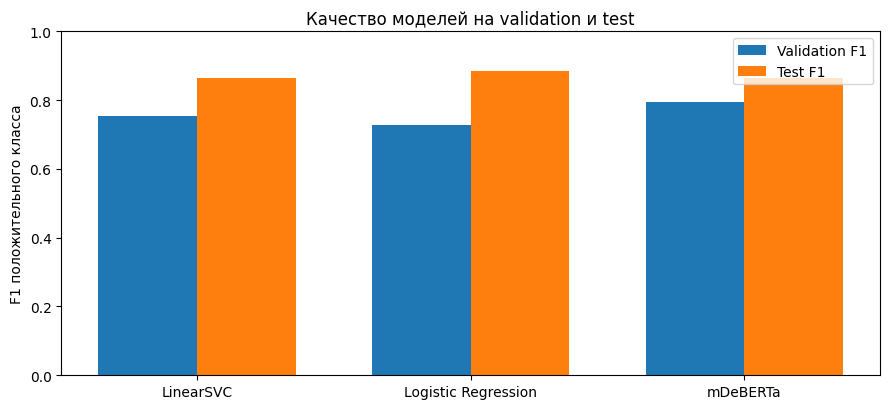

Лучший Test F1: LogisticRegression — 0.8861.
mDeBERTa: Test F1=0.8649; Precision=0.8889; Recall=0.8421.


In [10]:
# Тестовые метрики из сохранённых протоколов экспериментов.
with (DATA_DIR/'dl_test_metrics.json').open(encoding='utf-8') as fh:
    dl_test_record = json.load(fh)

dl_test_metrics = dl_test_record['metrics']
base_test = baseline.loc[baseline['split']=='test'].copy()
base_test['Модель'] = base_test['model']
dl_test = pd.DataFrame([{'Модель':'mDeBERTa', **dl_test_metrics}])

# Контроль численности выборки и независимый пересчёт F1 по матрицам ошибок.
test_rows = pd.concat([base_test, dl_test], ignore_index=True)
assert ((test_rows[['tp','fp','fn','tn']].sum(axis=1)) == 751).all()
assert ((test_rows['tp']+test_rows['fn']) == 38).all()
assert np.allclose(test_rows['f1'], calculate_metrics(test_rows)['f1_calc'])

# В основной таблице сравниваем три реальные обученные модели.
model_order = ['LinearSVC', 'LogisticRegression', 'mDeBERTa']
test_comp = test_rows.loc[test_rows['Модель'].isin(model_order)].copy()
test_comp['Модель'] = pd.Categorical(test_comp['Модель'], categories=model_order, ordered=True)
test_comp = test_comp.sort_values('Модель').reset_index(drop=True)

test_view = test_comp[['Модель','f1','precision','recall','ap','tp','fp','fn','tn']].rename(columns={
    'f1':'F1', 'precision':'Precision', 'recall':'Recall', 'ap':'AP',
    'tp':'TP','fp':'FP','fn':'FN','tn':'TN'
})
display(test_view.round(4))

# Наглядное сопоставление F1 на validation и test для одинаковых моделей.
plot_names = ['LinearSVC', 'LogisticRegression', 'mDeBERTa']
valid_lookup = {
    'LinearSVC': float(base_valid.set_index('model').loc['LinearSVC','f1']),
    'LogisticRegression': float(base_valid.set_index('model').loc['LogisticRegression','f1']),
    'mDeBERTa': float(winner['f1']),
}
test_lookup = test_comp.set_index('Модель')['f1'].to_dict()
positions = np.arange(len(plot_names))
width = 0.36
fig,ax = plt.subplots(figsize=(9,4.2))
ax.bar(positions-width/2,[valid_lookup[m] for m in plot_names],width,label='Validation F1')
ax.bar(positions+width/2,[test_lookup[m] for m in plot_names],width,label='Test F1')
ax.set_xticks(positions, ['LinearSVC','Logistic Regression','mDeBERTa'])
ax.set_ylim(0,1)
ax.set_ylabel('F1 положительного класса')
ax.set_title('Качество моделей на validation и test')
ax.legend()
plt.tight_layout()
plt.show()

best_test = test_comp.sort_values('f1',ascending=False).iloc[0]
print(f'Лучший Test F1: {best_test["Модель"]} — {best_test["f1"]:.4f}.')
print(f'mDeBERTa: Test F1={test_lookup["mDeBERTa"]:.4f}; '
      f'Precision={float(dl_test_metrics["precision"]):.4f}; '
      f'Recall={float(dl_test_metrics["recall"]):.4f}.')


## 10. Прикладная интерпретация: полезные предупреждения и пропущенные риски

Предположим, что модель используется для **предварительной фильтрации потока новостей**: аналитик получает сообщения с предсказанным риском и проверяет их вручную.

В такой системе высокая **Precision** означает меньше нерелевантных уведомлений, а высокая **Recall** — меньше пропущенных рискованных новостей. Обе характеристики важны, и приоритет одной зависит от сценария внедрения.

Сравним **реальные счётчики ошибок на test**, а не только усреднённые показатели. Для интерпретации используем два конкурирующих решения — mDeBERTa и Logistic Regression.

,Модель,Precision,Recall,F1,Число предупреждений,Верные предупреждения (TP),Ложные предупреждения (FP),Пропущенные риски (FN)
1,LogisticRegression,0.8537,0.9211,0.8861,41,35,6,3
2,mDeBERTa,0.8889,0.8421,0.8649,36,32,4,6


Precision mDeBERTa выше на 3.52 процентного пункта.
Ложных предупреждений у mDeBERTa меньше на 2 (4 вместо 6).
Всего предупреждений меньше на 5 (36 вместо 41).
При этом пропущенных рисков больше на 3 (6 вместо 3).


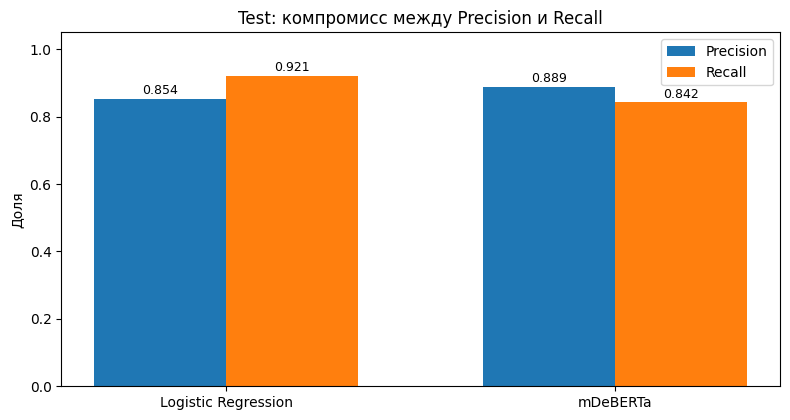

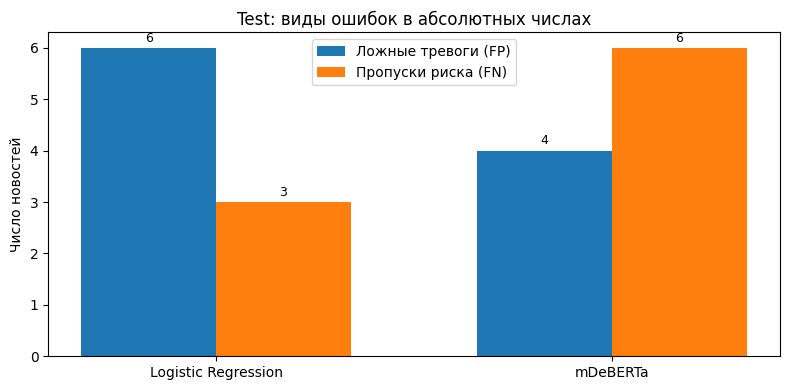

In [11]:
# Прикладные показатели непосредственно из сохранённых матриц ошибок.
practical = test_comp.loc[test_comp['Модель'].isin(['LogisticRegression', 'mDeBERTa'])].copy()
practical['Число предупреждений'] = (practical['tp'] + practical['fp']).astype(int)
practical['Верные предупреждения (TP)'] = practical['tp'].astype(int)
practical['Ложные предупреждения (FP)'] = practical['fp'].astype(int)
practical['Пропущенные риски (FN)'] = practical['fn'].astype(int)
practical_table = practical.rename(columns={
    'Модель':'Модель', 'precision':'Precision', 'recall':'Recall', 'f1':'F1'
})[['Модель','Precision','Recall','F1','Число предупреждений',
     'Верные предупреждения (TP)','Ложные предупреждения (FP)','Пропущенные риски (FN)']]
display(practical_table.round(4))

p = practical.set_index('Модель')
dl = p.loc['mDeBERTa']
lr = p.loc['LogisticRegression']
precision_delta_pp = (dl['precision'] - lr['precision']) * 100
fp_reduction = int(lr['fp'] - dl['fp'])
fn_growth = int(dl['fn'] - lr['fn'])
alerts_reduction = int((lr['tp'] + lr['fp']) - (dl['tp'] + dl['fp']))
assert (int(dl['tp']),int(dl['fp']),int(dl['fn'])) == (32,4,6)
assert (int(lr['tp']),int(lr['fp']),int(lr['fn'])) == (35,6,3)
print(f'Precision mDeBERTa выше на {precision_delta_pp:.2f} процентного пункта.')
print(f'Ложных предупреждений у mDeBERTa меньше на {fp_reduction} (4 вместо 6).')
print(f'Всего предупреждений меньше на {alerts_reduction} (36 вместо 41).')
print(f'При этом пропущенных рисков больше на {fn_growth} (6 вместо 3).')

# График показывает, что выигрыш Precision сопровождается потерей Recall.
plot_models = ['LogisticRegression','mDeBERTa']
xs = np.arange(len(plot_models))
fig, ax = plt.subplots(figsize=(8,4.3))
w=0.34
ax.bar(xs-w/2,[p.loc[m,'precision'] for m in plot_models],w,label='Precision')
ax.bar(xs+w/2,[p.loc[m,'recall'] for m in plot_models],w,label='Recall')
ax.set_xticks(xs,['Logistic Regression','mDeBERTa'])
ax.set_ylim(0,1.05)
ax.set_ylabel('Доля')
ax.set_title('Test: компромисс между Precision и Recall')
ax.legend()
for patch in ax.patches:
    ax.text(patch.get_x()+patch.get_width()/2,patch.get_height()+0.013,
            f'{patch.get_height():.3f}',ha='center',fontsize=9)
plt.tight_layout()
plt.show()

fig, ax=plt.subplots(figsize=(8,4.0))
ax.bar(xs-w/2,[p.loc[m,'fp'] for m in plot_models],w,label='Ложные тревоги (FP)')
ax.bar(xs+w/2,[p.loc[m,'fn'] for m in plot_models],w,label='Пропуски риска (FN)')
ax.set_xticks(xs,['Logistic Regression','mDeBERTa'])
ax.set_ylabel('Число новостей')
ax.set_title('Test: виды ошибок в абсолютных числах')
ax.legend()
for patch in ax.patches:
    ax.text(patch.get_x()+patch.get_width()/2,patch.get_height()+0.12,
            str(int(patch.get_height())),ha='center',fontsize=9)
plt.tight_layout()
plt.show()

### Интерпретация прикладных результатов

На тестовой выборке **mDeBERTa имеет наибольшую Precision среди сравниваемых моделей — 0,8889**. Для сценария ручной проверки предупреждений это потенциально полезно: среди срабатываний нейросети выше доля действительно рискованных новостей, а ложных тревог меньше (**4 против 6** у Logistic Regression).

Но сокращение ложных тревог сопровождается **дополнительными пропусками настоящего риска: 6 против 3**. Поэтому нейросеть **не является безусловно лучшей моделью раннего предупреждения**: для сценария, в котором важнее не пропустить риск, Logistic Regression здесь выглядит предпочтительнее.

Практическая ценность применения Deep Learning состоит в **возможности получить более точный поток положительных сигналов** при данном фиксированном пороге; это обоснование для сценария с акцентом на Precision, **а не доказательство общего превосходства**. Разница наблюдается на небольшой тестовой выборке и нуждается в подтверждении на новых данных. Эти результаты не означают, что Precision использовалась как критерий подбора: главным критерием выбора по-прежнему был validation F1.

## 11. Итоговые результаты бинарного этапа

Сопоставим качество моделей на validation и test, а также число ложных предупреждений и пропущенных рисков.

In [12]:
print('ИТОГИ БИНАРНОЙ КЛАССИФИКАЦИИ')
print('-' * 64)
print(f'Конфигураций mDeBERTa: {len(experiments)}')
print(f'Выбрана по validation F1: {winner_name}')
print(f'Validation F1: mDeBERTa={winner["f1"]:.4f}; '
      f'LinearSVC={best_classic["f1"]:.4f}; Δ={delta:+.4f}')
print(f'Test F1: Logistic Regression={float(lr["f1"]):.4f}; mDeBERTa={float(dl["f1"]):.4f}')
print(f'Test Precision: Logistic Regression={float(lr["precision"]):.4f}; '
      f'mDeBERTa={float(dl["precision"]):.4f}')
print(f'Test Recall: Logistic Regression={float(lr["recall"]):.4f}; '
      f'mDeBERTa={float(dl["recall"]):.4f}')
print(f'Ложные тревоги на test: LR={int(lr["fp"])}; DL={int(dl["fp"])}')
print(f'Пропущенные риски на test: LR={int(lr["fn"])}; DL={int(dl["fn"])}')
print(f'Устойчивость по seed: validation F1={seed_mean:.4f} ± {seed_sd:.4f} (SD)')

ИТОГИ БИНАРНОЙ КЛАССИФИКАЦИИ
----------------------------------------------------------------
Конфигураций mDeBERTa: 9
Выбрана по validation F1: screen_bank_context
Validation F1: mDeBERTa=0.7949; LinearSVC=0.7532; Δ=+0.0416
Test F1: Logistic Regression=0.8861; mDeBERTa=0.8649
Test Precision: Logistic Regression=0.8537; mDeBERTa=0.8889
Test Recall: Logistic Regression=0.9211; mDeBERTa=0.8421
Ложные тревоги на test: LR=6; DL=4
Пропущенные риски на test: LR=3; DL=6
Устойчивость по seed: validation F1=0.7465 ± 0.0486 (SD)


### Итоговый вывод бинарной части

В основной задаче выявления риска mDeBERTa получила наибольший validation F1 — 0,7949 против 0,7532 у LinearSVC и 0,7273 у Logistic Regression. На test Logistic Regression оказалась выше по F1: 0,8861 против 0,8649 у mDeBERTa.

Для рассматриваемого сценария мониторинга банковских новостей предпочтительной признана mDeBERTa: её Precision равна 0,8889 против 0,8537 у Logistic Regression, а число ложных предупреждений — 4 против 6. Такой профиль может снизить нагрузку на аналитиков, проверяющих сигналы вручную. Это прикладной выбор при приоритете точности предупреждений, а не доказательство универсального превосходства нейросети.

Logistic Regression остаётся сильной альтернативой и превосходит нейросеть по test F1 и Recall (0,9211 против 0,8421). При высокой стоимости пропуска риска она может быть предпочтительнее: пропущено 3 положительных примера против 6. Разница в ложных тревогах составляет лишь два случая на небольшом test, поэтому требует проверки на новых данных. Гиперпараметры, пороги и checkpoint выбирались по validation F1; Precision используется здесь для итоговой оценки практической пригодности.

## 12. Дополнительное исследование: тип банковского риска

Дополнительная постановка определяет один из четырёх классов: `no_risk`, `cyber_risk`, `operational_risk`, `regulatory_risk`. Сравнение выполнено на том же датасете и исходном разбиении. Основная метрика — Macro F1, которая не сопоставляется напрямую с бинарным F1.

На validation Logistic Regression получила 0,7446, mDeBERTa seed 42 — 0,7500. На test результаты составили соответственно 0,8206 и 0,7329. Для определения категории риска предпочтительной оказалась Logistic Regression. Подробности представлены в ноутбуках 07 и 11; дополнительные seed не заменяли основную нейросетевую модель.

In [13]:
# Проверка наличия четырёх классов в исходном неизменённом датасете.
classes = ['no_risk','cyber_risk','operational_risk','regulatory_risk']
multiclass_counts = pd.crosstab(dataset['split'],dataset['risk_type_4cls'])
multiclass_counts = multiclass_counts.reindex(index=['train','valid','test'],columns=classes,fill_value=0)
assert set(dataset['risk_type_4cls'].unique()) == set(classes)
assert (dataset['alert_flag'].to_numpy() == (dataset['risk_type_4cls'] != 'no_risk').astype(int).to_numpy()).all()
display(multiclass_counts)
print('Многоклассовая задача подготовлена к исследованию: метки уже есть в исходном CSV.')
print('Особое внимание: regulatory_risk — малочисленный класс, всего',int(multiclass_counts['regulatory_risk'].sum()),'наблюдений.')

risk_type_4cls,no_risk,cyber_risk,operational_risk,regulatory_risk
split,,,,
train,3359,74,67,35
valid,715,20,13,7
test,713,17,17,4


Многоклассовая задача подготовлена к исследованию: метки уже есть в исходном CSV.
Особое внимание: regulatory_risk — малочисленный класс, всего 46 наблюдений.


## 13. Ограничения и воспроизводимость

- **Небольшие положительные классы:** на validation всего 40 новостей о риске, на test — 38. Разница в двух ложных срабатываниях не является сама по себе доказательством устойчивого превосходства одной модели.
- **Разброс результатов по seed:** три обучения одной конфигурации дают различающиеся значения F1 на validation; требуются дополнительные независимые проверки для обобщения выводов.
- **Протокол test:** в ходе предыдущих экспериментальных итераций тестовые результаты уже анализировались. Поэтому итоговую оценку следует интерпретировать с оговоркой о возможном влиянии повторного анализа на разработку.
- **Пределы воспроизводимости:** Precision, Recall, F1 здесь действительно пересчитываются из сохранённых TP/FP/FN; AP берётся из файлов экспериментов. Код обучения включён в архив отдельно, а **веса лучшей mDeBERTa** сохранены в Kaggle Version #1 (`runs/screen_bank_context/best_model`) и не входят в архив.

Дополнительное многоклассовое исследование завершено; итоговое сравнение представлено в ноутбуке 11.